# Method_of_Sections
The rocket definition: airframe, aerodynamic surfaces, motor mounting, recovery, and the air-brake (AFC) hardware. It creates `rocket` and `air_brakes`, using `25_26_MoS_Parameters`, the `M2500T` motor, and `controller_function` from `AFC_Controller`.

### How this notebook loads its inputs
This notebook doesn't redefine any numbers; it reads them from the notebooks it depends on.
- **Opened on its own:** the cell below runs its dependencies with IPython's `%run` (written as `get_ipython().run_line_magic("run", ...)` because the call sits inside an `if`). When `%run` runs a notebook it executes in the **same namespace**, so every variable it defines becomes available here.
- **Run from `Test_Flight_MoS`:** that notebook sets `PIPELINE = True` and has already loaded everything, so this cell skips the reload. `SHOW_INFO` turns off the `.info()` printouts and plots so the test flight output stays clean.

In [15]:
from rocketpy import Rocket, SolidMotor, Environment, Flight   # simulation classes
import numpy as np                                              # arrays and maths
import pandas as pd                                             # reading .xlsx data files
import datetime                                                 # launch date for the forecast
import matplotlib.pyplot as plt                                 # plotting

Nozzle Details
Nozzle Radius: 0.033 m
Nozzle Throat Radius: 0.016 m

Grain Details
Number of Grains: 4
Grain Spacing: 0.004 m
Grain Density: 1724.1045383769072 kg/m3
Grain Outer Radius: 0.04 m
Grain Inner Radius: 0.016 m
Grain Height: 0.16 m
Grain Volume: 0.001 m3
Grain Mass: 1.165 kg

Motor Details
Total Burning Time: 4.264 s
Total Propellant Mass: 4.659 kg
Structural Mass Ratio: 0.422
Average Propellant Exhaust Velocity: 2054.731 m/s
Average Thrust: 2245.074 N
Maximum Thrust: 2861.69 N at 1.252 s after ignition.
Total Impulse: 9572.994 Ns



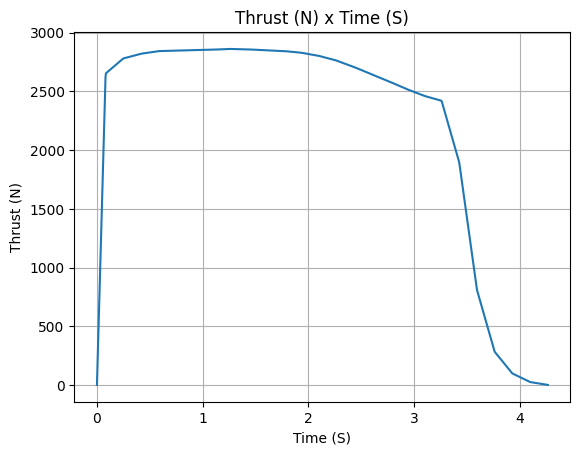

In [16]:
# PIPELINE is set to True by Test_Flight_MoS before it runs this notebook.
#   True  -> dependencies are already loaded; skip the info printouts and plots
#   False -> this notebook was opened on its own, so load what it needs first
PIPELINE = globals().get("PIPELINE", False)
if not PIPELINE:
    get_ipython().run_line_magic("run", "25_26_MoS_Parameters.ipynb")   # load 25_26_MoS_Parameters
    get_ipython().run_line_magic("run", "M2500T.ipynb")   # load M2500T
    get_ipython().run_line_magic("run", "AFC_Controller.ipynb")   # load AFC_Controller
SHOW_INFO = not PIPELINE   # only print .info() / draw plots when run on its own

## Airframe
- **`Rocket(...)`:** the motor-less mass properties from the parameters notebook, plus the drag curves. `radius` sets the reference area for every Cd. `power_off_drag` is used during the coast and `power_on_drag` during the burn.
- **`coordinate_system_orientation="nose_to_tail"`:** every position below is measured from the nose tip toward the tail, matching OpenRocket.

In [17]:
rocket = Rocket(
    radius=BODY_RADIUS,                       # m, also sets the reference area pi*r^2
    mass=DRY_MASS,                            # kg without motor
    inertia=DRY_INERTIA,                      # kg*m^2 about the dry CG
    power_off_drag=CD,                        # RASAero Cd vs Mach, coast
    power_on_drag=CD,                         # same curve used during the burn
    center_of_mass_without_motor=DRY_CG,      # m from nose tip
    coordinate_system_orientation="nose_to_tail",
    )

## Aerodynamic surfaces
These give the rocket its **lift and CP**, which RocketPy combines into the restoring moment and the stability margin. They add no drag; all the drag comes from the RASAero curve. Their geometry should match what you entered in RASAero, so the drag and the CP describe the same rocket.

In [18]:
rocket.add_nose(
    length=NOSE_LENGTH,                       # m
    kind=NOSE_KIND,                           # "vonKarman"
    position=NOSE_POSITION, name="Nose Cone"  # tip at the origin
    )
rocket.add_trapezoidal_fins(
    n=FIN_COUNT,                              # 3 fins
    root_chord=FIN_ROOT_CHORD,                # m
    tip_chord=FIN_TIP_CHORD,                  # m
    span=FIN_SPAN,                            # m
    sweep_length=FIN_SWEEP_LENGTH,            # m
    position=FIN_POSITION,                    # m, leading edge of the root
    cant_angle=FIN_CANT,                      # deg
    name="Fins",
    )
rocket.add_tail(
    top_radius=TAIL_TOP_RADIUS,               # m
    bottom_radius=TAIL_BOTTOM_RADIUS,         # m
    length=TAIL_LENGTH,                       # m
    position=TAIL_POSITION,                   # m, start of the taper
    name="Boat Tail"
    )

## Rail buttons and motor
- **`set_rail_buttons`:** the effective rail length is the rail length minus the distance from the nozzle to the upper button, so the button positions set the rail exit time and velocity (DTEG 5.3).
- **`add_motor`:** places the motor's origin (its nozzle exit) at `MOTOR_POSITION`. From then on, RocketPy combines the motor's changing mass, CG and inertia with the airframe's.

In [19]:
rocket.set_rail_buttons(
    upper_button_position=RAIL_BUTTON_UPPER,  # m, forward button: sets the effective rail length
    lower_button_position=RAIL_BUTTON_LOWER,  # m, aft button
    angular_position=RAIL_BUTTON_ANGLE        # deg around the body
    )
rocket.add_motor(
    M2500T,
    position=MOTOR_POSITION                   # m, where the motor's nozzle exit sits
    )

## Recovery
- **`trigger`:** `"apogee"` deploys when vertical velocity goes negative. A number deploys at that **height above ground**, in metres, on the way down.
- **`lag`:** the delay from the trigger to the parachute being fully open, in seconds. The 1 s main lag matches the main's deployment delay in the `.ork`.
- **Main CdS:** the drogue, pilot and main together, because RocketPy replaces the descent drag when a new parachute deploys and all three are out on the real rocket.

In [20]:
rocket.add_parachute(
    "Drogue",
    cd_s=DROGUE_CDS,                          # m^2
    trigger="apogee",                         # deploy at apogee
    lag=0.0                                   # s
    )
rocket.add_parachute(
    "Main",
    cd_s=DROGUE_CDS + PILOT_CDS + MAIN_CDS,   # m^2, everything open under main
    trigger=MAIN_DEPLOY_ALT, lag=1.0          # m AGL, s
    )

<Parachute Main (cd_s = 7.0799 m2, trigger = 457.2)>

## Air brakes (AFC)
- **`drag_coefficient_curve`:** the 3-column (deployment, Mach, Cd) table. RocketPy interpolates it in both deployment and Mach.
- **`reference_area=None`:** the brake Cd uses the rocket's own reference area π·`BODY_RADIUS`².
- **`override_rocket_drag=False`:** the brake Cd is **added** to the RASAero rocket Cd. If it were `True`, the table would have to be the whole rocket's Cd with the brakes out.
- **`clamp=True`:** keeps the deployment level between 0 and 1 even if the controller asks for more.
- **`initial_observed_variables`:** the starting value of the controller's saved output, matching its `(time, deployment, Cd)` return.

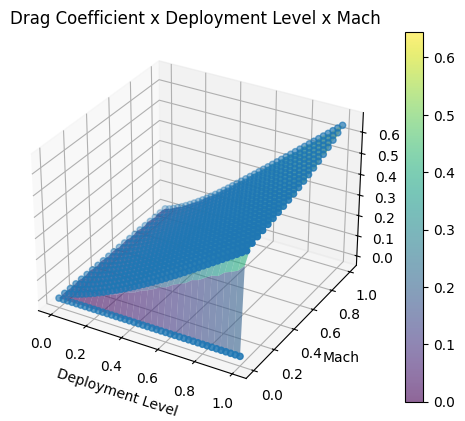

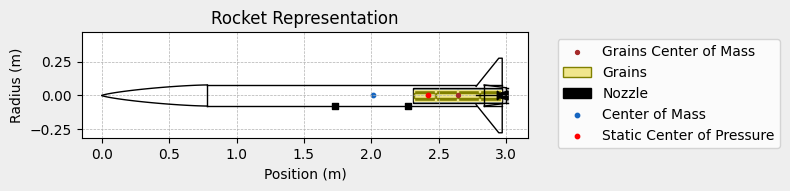

In [21]:
air_brakes = rocket.add_air_brakes(
    drag_coefficient_curve=AFC_Drag_Data,     # columns: deployment level, Mach, Cd
    controller_function=controller_function,  # from AFC_Controller
    sampling_rate=AIRBRAKE_SAMPLING_RATE,     # Hz
    reference_area=None,                      # use rocket reference area
    clamp=True,                               # keep deployment within [0, 1]
    initial_observed_variables=[0, 0, 0],     # (time, deployment, Cd) before the first call
    override_rocket_drag=False,               # brake Cd is added to the rocket Cd
    name="Air Brakes"
)

if SHOW_INFO:
    air_brakes.all_info()                     # brake Cd surface vs deployment and Mach
    rocket.draw()                             # side view: check geometry and positions
    #rocket.plots.static_margin()